# [GSE97889](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE97889)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-09-25
> - Modified: 2025-05-03

# 1. Experimental Design

> NicE-seq: high resolution open chromatin profiling.
> - Ponnaluri, V.K.C., Zhang, G., Estève, PO. et al. NicE-seq: high resolution open chromatin profiling. Genome Biol 18, 122 (2017). https://doi.org/10.1186/s13059-017-1247-6.
> - WGBS, EZ DNA Methylation Kit (Zymo Research)
> - Illumina NextSeq 500, PE150
> - Bismark-Bowtie2, hg19

| Sample | Organism | Cell | Tissue | Treatment | Replicate |
| - | - | - | - | - | - |
| Control | Homo sapiens | HCT116 | Colonic epithelial cells | Control | rep1~2 |
| Decitabine | Homo sapiens | HCT116 | Colonic epithelial cells | Decitabine (5 µM, 6 days) | rep1~2 |

> Notes:
> - Decitabine (5 µM) for 6 days, with media replacement and fresh drug added on day 2.
> - The bismark cov file provided by GEO contains bases that do not belong to CpG sites, which may be due to differences in genome versions.

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/wgbs_Hs_HCT116_5Aza_GSE97889"

gtf_file <- "~/reference/Homo_sapiens/hg19/gencode.v19.annotation.gtf"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Hsapiens.UCSC.hg19))
genome <- BSgenome.Hsapiens.UCSC.hg19

suppressPackageStartupMessages(library(TxDb.Hsapiens.UCSC.hg19.knownGene))
txdb <- TxDb.Hsapiens.UCSC.hg19.knownGene

# 2. Import Data

## 1). Import Bismark Cov

In [ ]:
# Load Bismark coverage file as GRanges
load_bismark_cov <- function(
    file, cov = 5, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE) {

    gr <- data.table::fread(
        file, header = FALSE, sep = "\t", 
        col.names = c("chr", "start", "end", "meth", "numCs", "numTs")) |>
        dplyr::filter((numCs + numTs) >= cov) |>
        GRanges()

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    return(gr)
}

# BRGenomics::tidyChromosomes(keep.X = FALSE, keep.Y = FALSE, keep.M = FALSE)

In [5]:
file_pattern <- "^GSM\\d+_(.*)\\.bismark\\.cov\\.txt\\.gz$"

cov_files <- file.path(data_dir, "00_geo") |>
    list.files(pattern = file_pattern, full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

paste(names(cov_files), basename(cov_files), sep = ": ") |> cat(sep = "\n")

HCT116_Decitabine_rep1: GSM2579640_HCT116_Decitabine_rep1.bismark.cov.txt.gz
HCT116_Decitabine_rep2: GSM2579641_HCT116_Decitabine_rep2.bismark.cov.txt.gz
HCT116_Control_rep1: GSM2579642_HCT116_Control_rep1.bismark.cov.txt.gz
HCT116_Control_rep2: GSM2579643_HCT116_Control_rep2.bismark.cov.txt.gz


In [6]:
cov_list <- lapply(cov_files, cov = 0, load_bismark_cov, dropSex = FALSE)
cov_list <- cov_list[order(names(cov_list))]

cov_list[1]

$HCT116_Control_rep1
GRanges object with 44349729 ranges and 3 metadata columns:
             seqnames    ranges strand |      meth     numCs     numTs
                <Rle> <IRanges>  <Rle> | <numeric> <integer> <integer>
         [1]     chr8     10782      * |       100         2         0
         [2]     chr8     10862      * |       100         2         0
         [3]     chr8     10888      * |       100         2         0
         [4]     chr8     10927      * |         0         0         2
         [5]     chr8     11714      * |       100         1         0
         ...      ...       ...    ... .       ...       ...       ...
  [44349725]     chrY  59241013      * |       100         1         0
  [44349726]     chrY  59247243      * |       100         1         0
  [44349727]     chrY  59247259      * |       100         1         0
  [44349728]     chrY  59280748      * |       100         1         0
  [44349729]     chrY  59280827      * |       100         1       

In [7]:
coldata <- data.frame(sample = names(cov_list)) |>
    separate(
        sample, into = c("Cell", "Group", "Replicate"),
        sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("Control", "Decitabine")),
        Replicate = factor(Replicate)) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Replicate
,<chr>,<fct>,<fct>
HCT116_Control_rep1,HCT116,Control,rep1
HCT116_Control_rep2,HCT116,Control,rep2
HCT116_Decitabine_rep1,HCT116,Decitabine,rep1
HCT116_Decitabine_rep2,HCT116,Decitabine,rep2


## 2). CpG Aggregation

> Strand-aware CpG methylation aggregation
> - CpG methylation calls from the Watson and Crick strands were combined to produce unified CpG-level profiles. For each CpG site, strand-specific methylated (C) and unmethylated (T) read counts were summed, and methylation levels were recalculated as the ratio of total methylated reads to total coverage across both strands. This aggregation strategy provides a single, strand-independent representation of CpG methylation for downstream analysis.

In [8]:
Biostrings::vmatchPattern("CG", genome) |>
    GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
    GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")

GRanges object with 56434018 ranges and 0 metadata columns:
             seqnames            ranges strand
                <Rle>         <IRanges>  <Rle>
         [1]     chr1       10469-10470      +
         [2]     chr1       10471-10472      +
         [3]     chr1       10484-10485      +
         [4]     chr1       10489-10490      +
         [5]     chr1       10493-10494      +
         ...      ...               ...    ...
  [56434014]     chrY 59362433-59362434      -
  [56434015]     chrY 59362485-59362486      -
  [56434016]     chrY 59362488-59362489      -
  [56434017]     chrY 59362493-59362494      -
  [56434018]     chrY 59362591-59362592      -
  -------
  seqinfo: 24 sequences from hg19 genome

In [9]:
# Extracting CpG sites from genome
CpGs <- lapply(seqnames(genome), function(chr) {
    seq <- getSeq(genome, chr)
    pos <- Biostrings::matchPattern("CG", seq)
    GRanges(chr, IRanges(start = start(pos), end = end(pos)), strand = "+")
}) |>
    GRangesList() |> unlist() |>
    GenomeInfoDb::keepStandardChromosomes(pruning.mode = "coarse") |>
    GenomeInfoDb::dropSeqlevels("chrM", pruning.mode = "coarse")

CpGs

GRanges object with 28217009 ranges and 0 metadata columns:
             seqnames            ranges strand
                <Rle>         <IRanges>  <Rle>
         [1]     chr1       10469-10470      +
         [2]     chr1       10471-10472      +
         [3]     chr1       10484-10485      +
         [4]     chr1       10489-10490      +
         [5]     chr1       10493-10494      +
         ...      ...               ...    ...
  [28217005]     chrY 59362433-59362434      +
  [28217006]     chrY 59362485-59362486      +
  [28217007]     chrY 59362488-59362489      +
  [28217008]     chrY 59362493-59362494      +
  [28217009]     chrY 59362591-59362592      +
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths

In [ ]:
aggregate_cpg_methylation <- function(input, cpg, cov = 5) {
    message("Aggregating methylation to CpG sites...")

    hits <- GenomicRanges::findOverlaps(cpg, input, ignore.strand = TRUE)

    if (length(hits) == 0) return(NULL)

    df <- data.table::data.table(
        cpg_idx = queryHits(hits),
        numCs = input$numCs[subjectHits(hits)],
        numTs = input$numTs[subjectHits(hits)]
    )

    agg <- df[, .(numCs = sum(numCs), numTs = sum(numTs)), by = cpg_idx]
    agg <- agg[(numCs + numTs) >= cov]

    if (nrow(agg) == 0) return(NULL)

    result <- cpg[agg$cpg_idx]
    result$meth <- with(agg, numCs / (numCs + numTs) * 100)
    result$numCs <- agg$numCs
    result$numTs <- agg$numTs

    return(result)
}

In [11]:
meth_list <- lapply(cov_list, aggregate_cpg_methylation, cpg = CpGs, cov = 0)

meth_list[1]

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...

Aggregating methylation to CpG sites...



$HCT116_Control_rep1
GRanges object with 25979865 ranges and 3 metadata columns:
             seqnames            ranges strand |      meth     numCs     numTs
                <Rle>         <IRanges>  <Rle> | <numeric> <integer> <integer>
         [1]     chr1       10469-10470      + |   66.6667         2         1
         [2]     chr1       10471-10472      + |   66.6667         2         1
         [3]     chr1       10484-10485      + |   80.0000         4         1
         [4]     chr1       10489-10490      + |  100.0000         5         0
         [5]     chr1       10493-10494      + |  100.0000         5         0
         ...      ...               ...    ... .       ...       ...       ...
  [25979861]     chrY 59241012-59241013      + |       100         1         0
  [25979862]     chrY 59247243-59247244      + |       100         1         0
  [25979863]     chrY 59247259-59247260      + |       100         1         0
  [25979864]     chrY 59280748-59280749      + |  

In [12]:
# Export bw files for visualization in IGV
lapply(names(meth_list), function(idx){
    gr <- meth_list[[idx]]
    mcols(gr)[["score"]] <- mcols(gr)[["meth"]]
    seqinfo(gr) <- seqinfo(genome)[seqlevels(gr)]
    export.bw(gr, file.path(data_dir, "00_geo", paste0(idx, ".bw")))
}) |> invisible()

# 3. Evaluate Library Quality

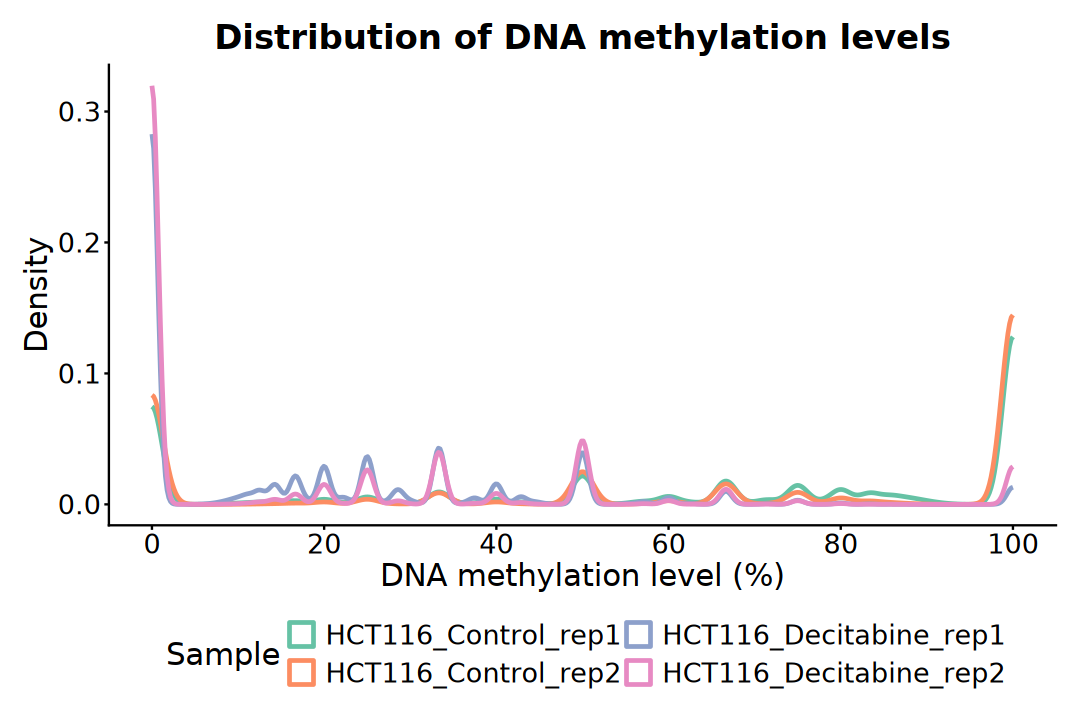

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    ggplot(aes(x = meth, color = sample)) +
    geom_density(linewidth = 1) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Density", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# Discrete peaks in methylation levels are observed due to low coverage.

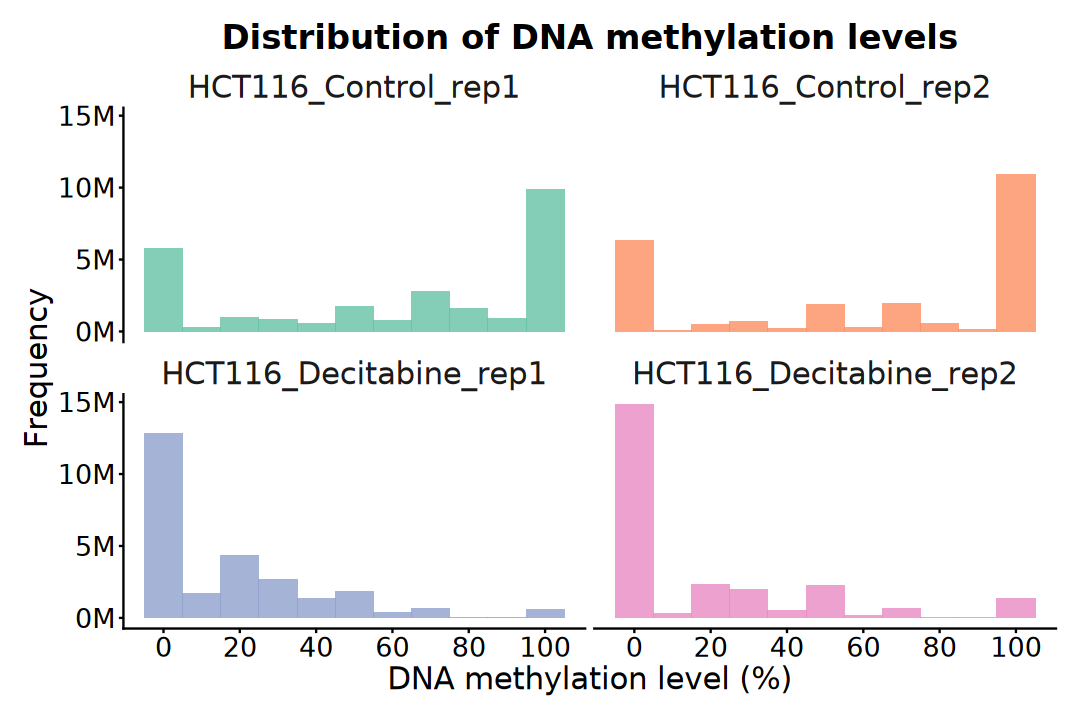

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    ggplot(aes(x = meth, fill = sample)) +
    geom_histogram(binwidth = 10, position = "identity", alpha = 0.8) +
    facet_wrap(~ sample, ncol = 2) +
    scale_x_continuous(breaks = seq(0, 100, 20)) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Distribution of DNA methylation levels",
        x = "DNA methylation level (%)", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

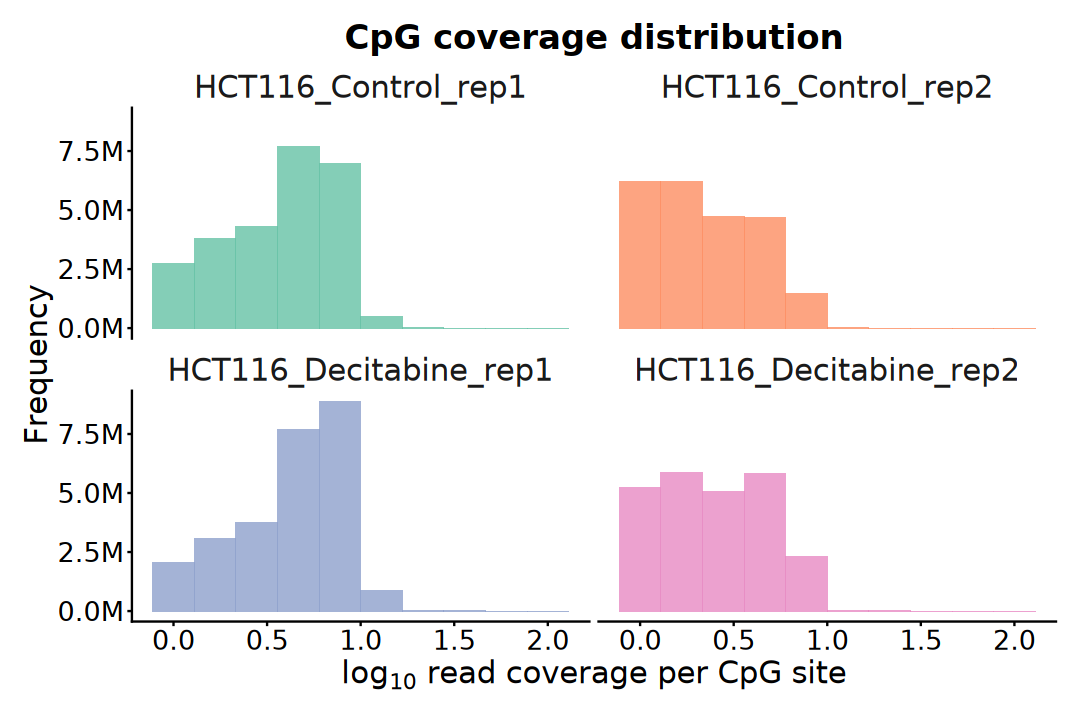

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::mutate(coverage = numCs + numTs) |>
    dplyr::select(sample, coverage) |>
    dplyr::filter(coverage <= 100) |>
    ggplot(aes(x = log10(coverage), fill = sample)) +
    geom_histogram(bins = 10, alpha = 0.8) +
    facet_wrap( ~ sample, ncol = 2) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG coverage distribution",
        x = expression(log[10] ~ "read coverage per CpG site"),
        y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Global Methylation

## 1). Standard Plot

In [16]:
plot_df <- data.frame(
    sample = names(meth_list),
    number = sapply(meth_list, length),
    mean = sapply(meth_list, \(gr) mean(mcols(gr)$meth))) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    column_to_rownames("sample")

plot_df

,number,mean,Cell,Group,Replicate
,<int>,<dbl>,<chr>,<fct>,<fct>
HCT116_Control_rep1,25979865,61.33124,HCT116,Control,rep1
HCT116_Control_rep2,23353725,61.32282,HCT116,Control,rep2
HCT116_Decitabine_rep1,26364549,17.99113,HCT116,Decitabine,rep1
HCT116_Decitabine_rep2,24320078,18.23091,HCT116,Decitabine,rep2


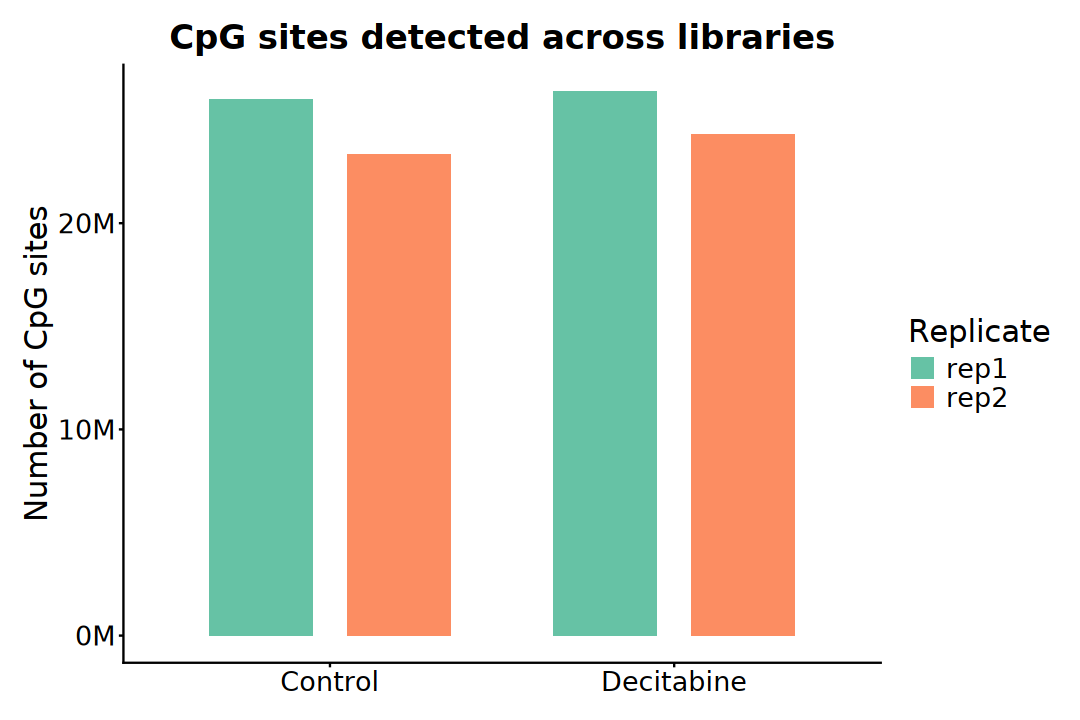

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG sites detected across libraries", 
        x = NULL, y = "Number of CpG sites") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "right", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

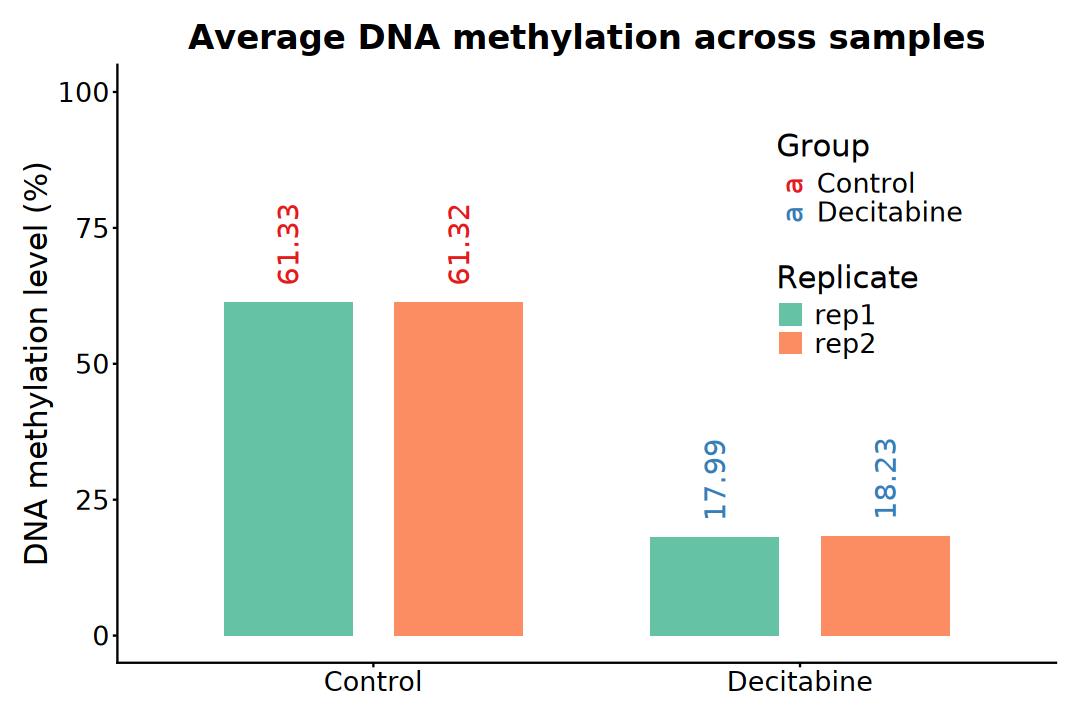

In [18]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = mean, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    geom_text(
        aes(color = Group, label = sprintf("%.2f", round(mean, 2))),
        position = position_dodge(width = 0.8),
        angle = 90, vjust = 0.5, hjust = -0.2, size = 6) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set1") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "inside",
        legend.position.inside = c(0.8, 0.7),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [19]:
plot_df <- map_dfr(meth_list, ~ tibble(
    meth = mcols(.x)$meth), .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

head(plot_df)

sample,meth,Cell,Group,Replicate
<chr>,<dbl>,<chr>,<fct>,<fct>
HCT116_Control_rep1,66.66667,HCT116,Control,rep1
HCT116_Control_rep1,66.66667,HCT116,Control,rep1
HCT116_Control_rep1,80.00000,HCT116,Control,rep1
HCT116_Control_rep1,100.00000,HCT116,Control,rep1
HCT116_Control_rep1,100.00000,HCT116,Control,rep1
HCT116_Control_rep1,71.42857,HCT116,Control,rep1


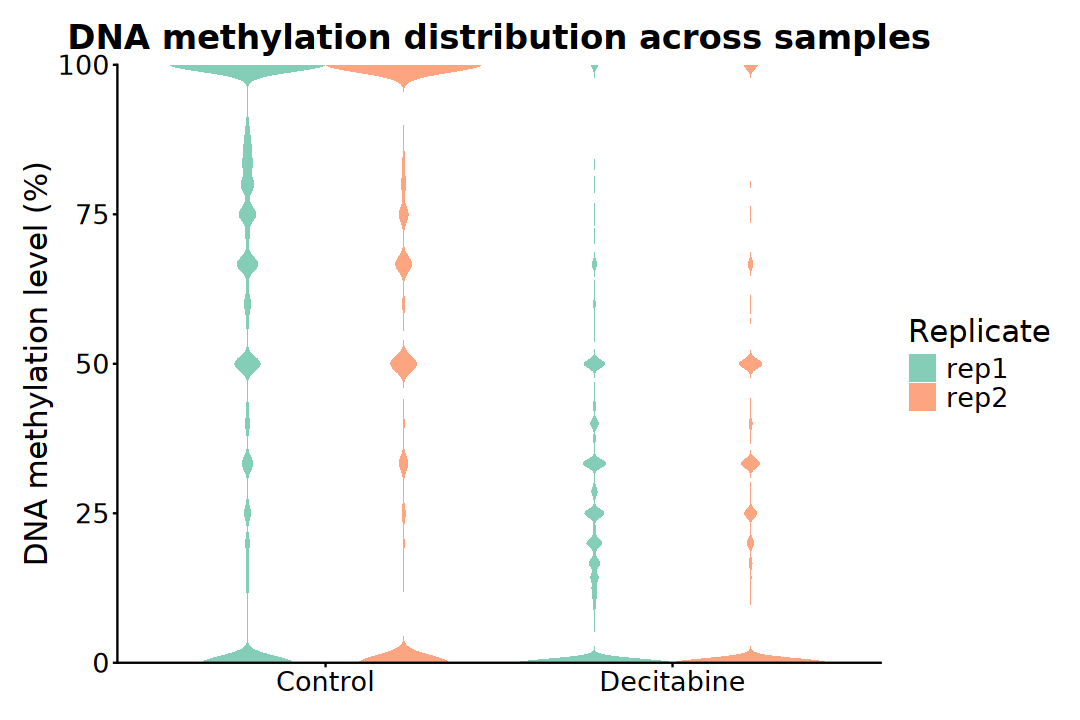

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = meth, fill = Replicate)) +
    geom_violin(trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    # geom_boxplot(
    #     width = 0.2, outlier.shape = NA, color = "grey50",
    #     position = position_dodge(width = 0.9)) +
    # stat_summary(
    #     fun = median, geom = "point", size = 2, color = "black",
    #     position = position_dodge(width = 0.9)) +
    scale_y_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "DNA methylation distribution across samples",
        x = NULL, y = "DNA methylation level (%)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Density Scatter Plot

In [21]:
common_cpg <- Reduce(function(x, y) {
    x[findOverlaps(x, y, type = "equal") |> queryHits()]
}, meth_list) |> granges()

common_cpg

GRanges object with 20256647 ranges and 0 metadata columns:
             seqnames            ranges strand
                <Rle>         <IRanges>  <Rle>
         [1]     chr1       10469-10470      +
         [2]     chr1       10471-10472      +
         [3]     chr1       10484-10485      +
         [4]     chr1       10489-10490      +
         [5]     chr1       10493-10494      +
         ...      ...               ...    ...
  [20256643]     chrY 59033091-59033092      +
  [20256644]     chrY 59033101-59033102      +
  [20256645]     chrY 59033172-59033173      +
  [20256646]     chrY 59033236-59033237      +
  [20256647]     chrY 59033246-59033247      +
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths

In [22]:
meth_common <- lapply(meth_list, function(gr) {
    hits <- findOverlaps(common_cpg, gr, type = "equal")
    meth <- rep(NA_real_, length(common_cpg))
    meth[queryHits(hits)] <- gr$meth[subjectHits(hits)]
    meth
})

meth_common <- as.data.frame(meth_common)
names(meth_common) <- names(meth_list)

head(meth_common)

,HCT116_Control_rep1,HCT116_Control_rep2,HCT116_Decitabine_rep1,HCT116_Decitabine_rep2
,<dbl>,<dbl>,<dbl>,<dbl>
1,66.66667,75.00000,25.00000,0.00000
2,66.66667,100.00000,28.57143,0.00000
3,80.00000,100.00000,33.33333,12.50000
4,100.00000,83.33333,33.33333,12.50000
5,100.00000,71.42857,33.33333,14.28571
6,71.42857,57.14286,28.57143,12.50000


In [23]:
sample_pairs <- combn(names(meth_list), 2, simplify = FALSE)

plot_list <- lapply(sample_pairs, function(pair) {
    ggplot(meth_common, aes(.data[[pair[1]]], .data[[pair[2]]])) +
        geom_bin2d(bins = 100) +
        geom_abline(
            slope = 1, intercept = 0, linetype = "dashed",
            color = "lightcoral", linewidth = 1) +
        scale_fill_gradientn(
            colors = viridis(256), trans = "log10", name = "Count (log10)") +
        coord_fixed() +
        labs(title = "DNA methylation comparison", x = pair[1], y = pair[2]) +
        theme_bw() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            legend.position = "right",
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
})

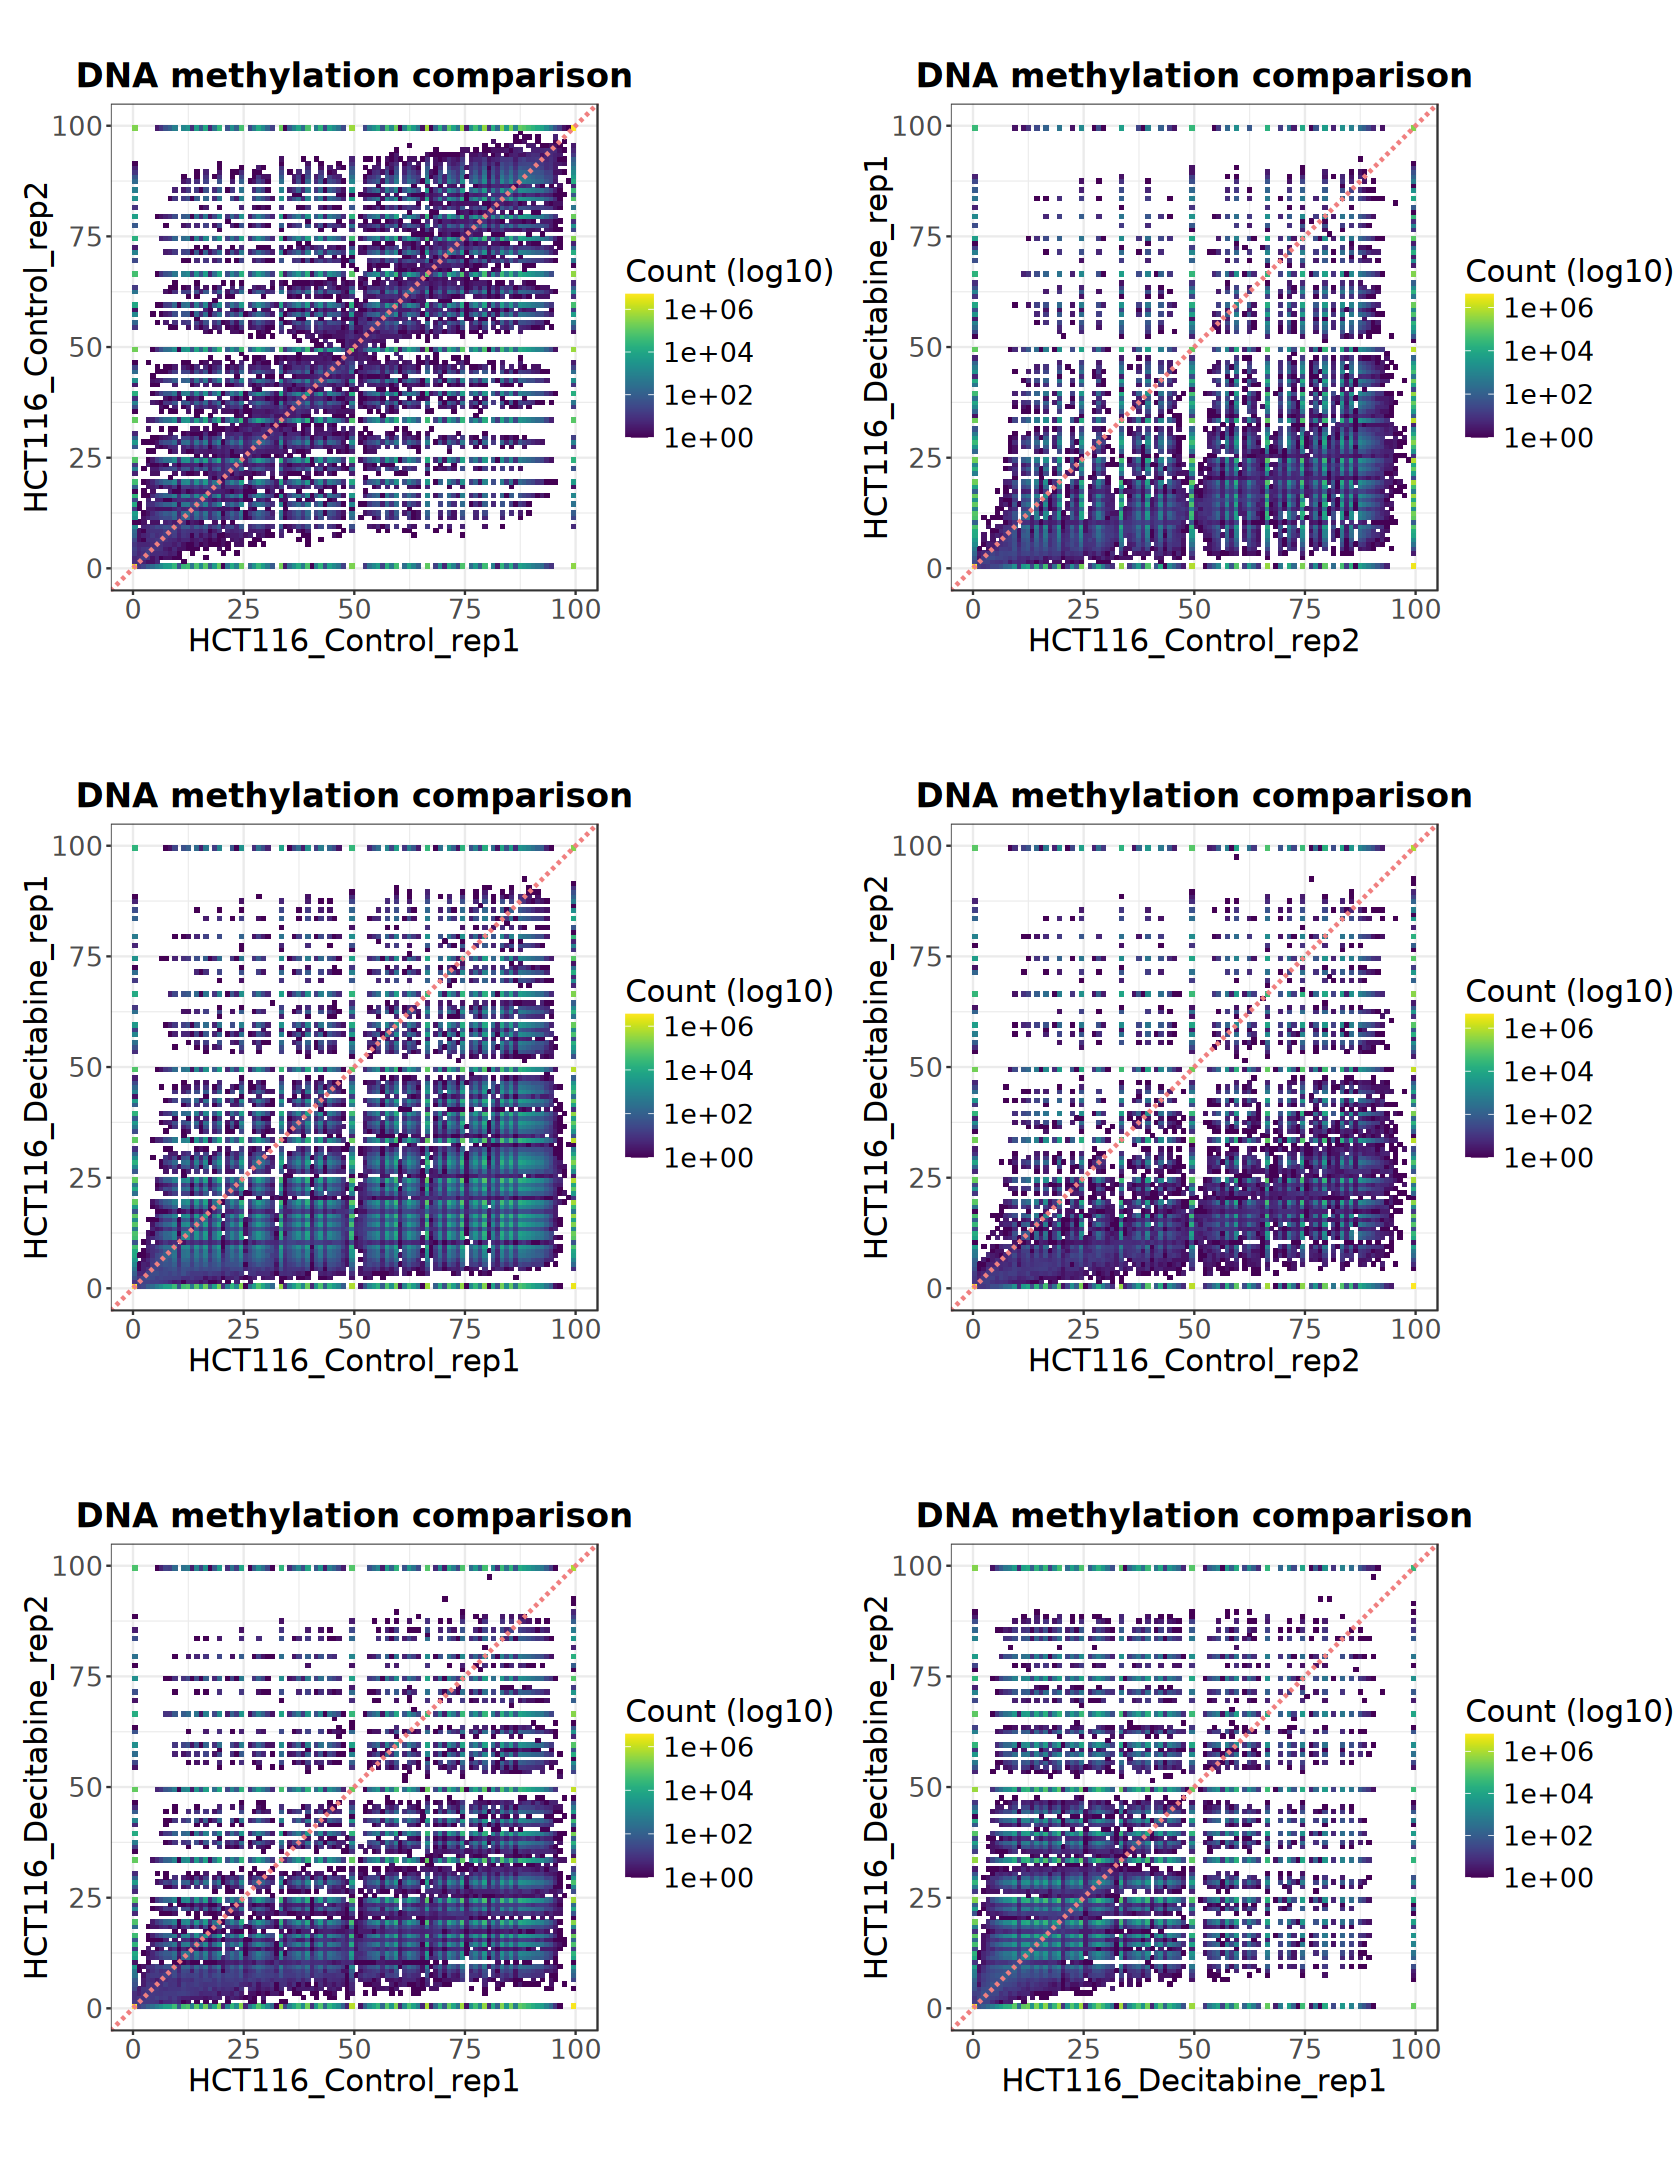

In [24]:
options(repr.plot.width = 14, repr.plot.height = 18)

plot_grid(plotlist = plot_list, nrow = 3, ncol = 2, byrow = FALSE)

In [25]:
plot_methylation_comparison <- function(plot_df, sample_x, sample_y) {
    # Linear regression
    fit <- lm(methy_y ~ methy_x, data = plot_df)

    # Spearman correlation
    cor_res <- cor.test(
        plot_df$methy_x, plot_df$methy_y, method = "spearman", exact = FALSE)

    # scatter plot
    smoothScatter(
        plot_df$methy_x, plot_df$methy_y,
        colramp = colorRampPalette(brewer.pal(9, "Blues")),
        xlab = sample_x, ylab = sample_y, cex = 0)
    abline(a = 0, b = 1, col = "darkblue", lty = 2, lwd = 3)
    abline(fit, col = "darkred", lty = 2, lwd = 3)
    legend(
        "topleft", lty = 2, lwd = 2, col = 'black', border = NA, 
        text.col = "black", box.col = NA, bg = NA,
        legend = c(
            paste0("Linear slope: ", round(coef(fit)[2], 2)),
            paste0("Spearman \u03c1: ", round(cor_res$estimate, 2)),
            paste0("P-value: ", format.pval(
                cor_res$p.value, digits = 2, eps = 1e-100))))
}

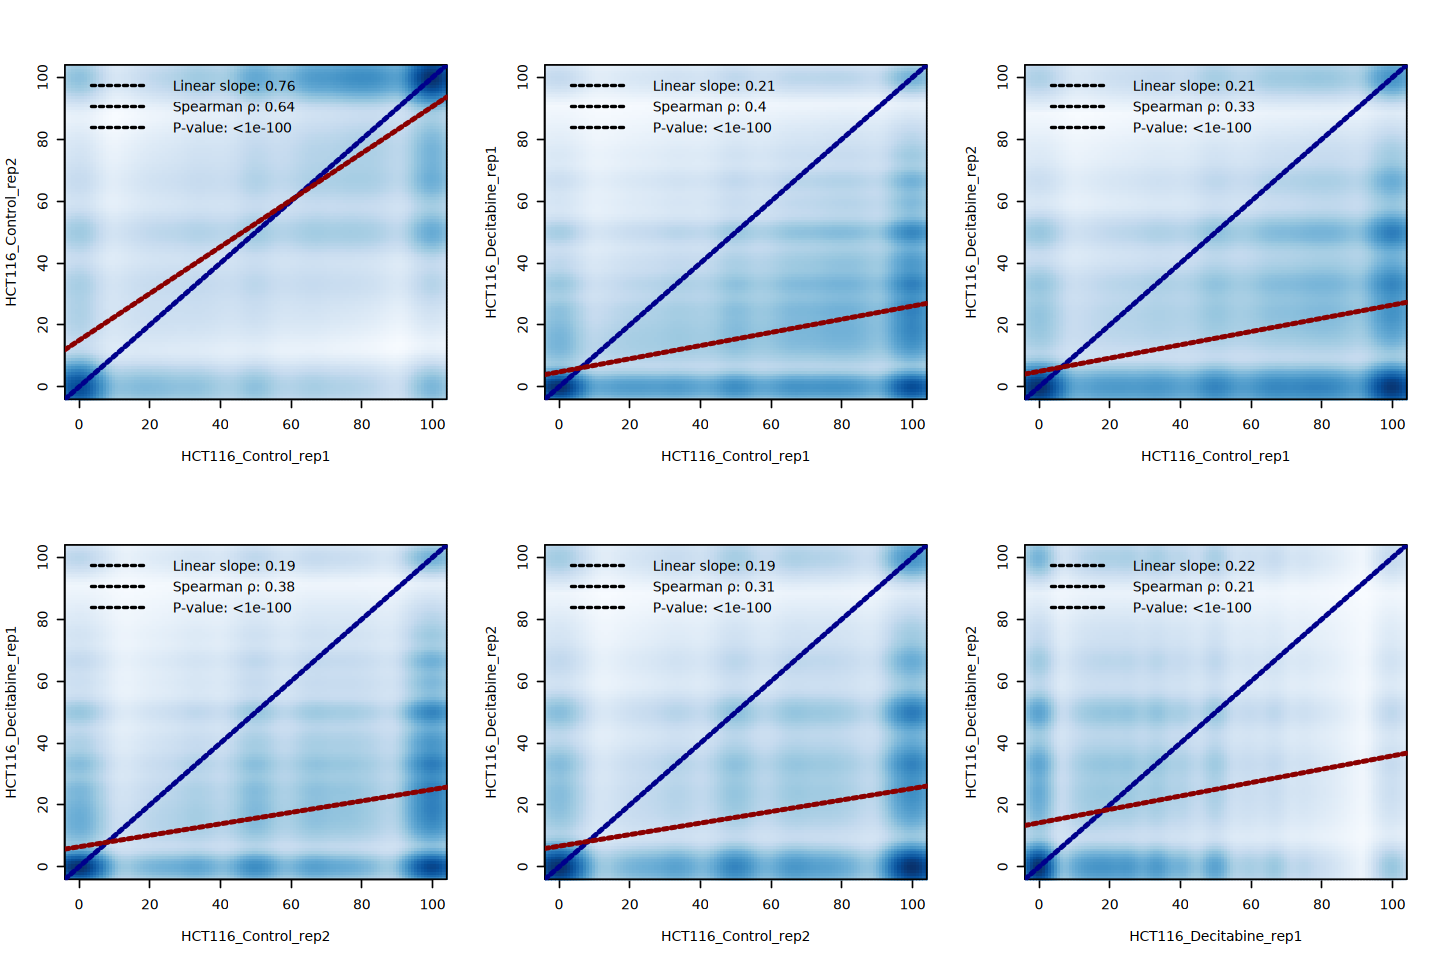

In [26]:
options(repr.plot.width = 12, repr.plot.height = 8)

par(mfrow = c(2, 3))

for (pair in combn(names(meth_list), 2, simplify = FALSE)) {
    plot_df <- data.frame(
        methy_x = meth_common[[pair[1]]],
        methy_y = meth_common[[pair[2]]])
    plot_methylation_comparison(plot_df, pair[1], pair[2])
}

## 3). Circular Genome-wide Plot

In [27]:
suppressPackageStartupMessages(library(circlize))

In [28]:
# 1. Read and process chromosome sizes
chrom_sizes <- seqlengths(genome)
standard_chromosome <- c(paste0("chr", 1:22), "chrX", "chrY")
chrom_sizes <- chrom_sizes[names(chrom_sizes) %in% standard_chromosome]

# 2. Generate genomic bins (1Mb window)
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)

In [29]:
# 3. Calculate mean methylation level for each bins.
bin_stats_list <- lapply(names(meth_list), function(idx) {
    gr <- meth_list[[idx]]
    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        numCs = gr$numCs[queryHits(hits)],
        numTs = gr$numTs[queryHits(hits)])

    bin_stats <- df[, list(
        numCs = sum(numCs), numTs = sum(numTs)), by = bin_idx]
    bin_stats[, meth := numCs / (numCs + numTs)]

    result <- bins[bin_stats$bin_idx]
    result$meth <- bin_stats$meth
    result$numCs <- bin_stats$numCs
    result$numTs <- bin_stats$numTs
    result$sample <- idx
    names(result) <- NULL
    return(result)
})

In [30]:
# 4. Prepare data frames for plotting
bin_df <- do.call(c, bin_stats_list) |> as.data.frame() |>
    dplyr::select(chr = seqnames, start, end, sample, meth) |>
    dplyr::mutate(meth = meth * 100) |>
    pivot_wider(
        id_cols = c("chr", "start", "end"),
        names_from = "sample", values_from = "meth")

head(bin_df)

chr,start,end,HCT116_Control_rep1,HCT116_Control_rep2,HCT116_Decitabine_rep1,HCT116_Decitabine_rep2
<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
chr1,1,1000000,39.46370,39.19353,11.396625,10.61072
chr1,1000001,2000000,62.64541,61.13785,18.088830,18.58626
chr1,2000001,3000000,55.68864,56.44151,16.135887,16.85754
chr1,3000001,4000000,64.25918,65.10146,18.958096,19.16777
chr1,4000001,5000000,24.14785,24.01464,8.062216,8.95477
chr1,5000001,6000000,32.69146,32.32297,10.154143,10.41688


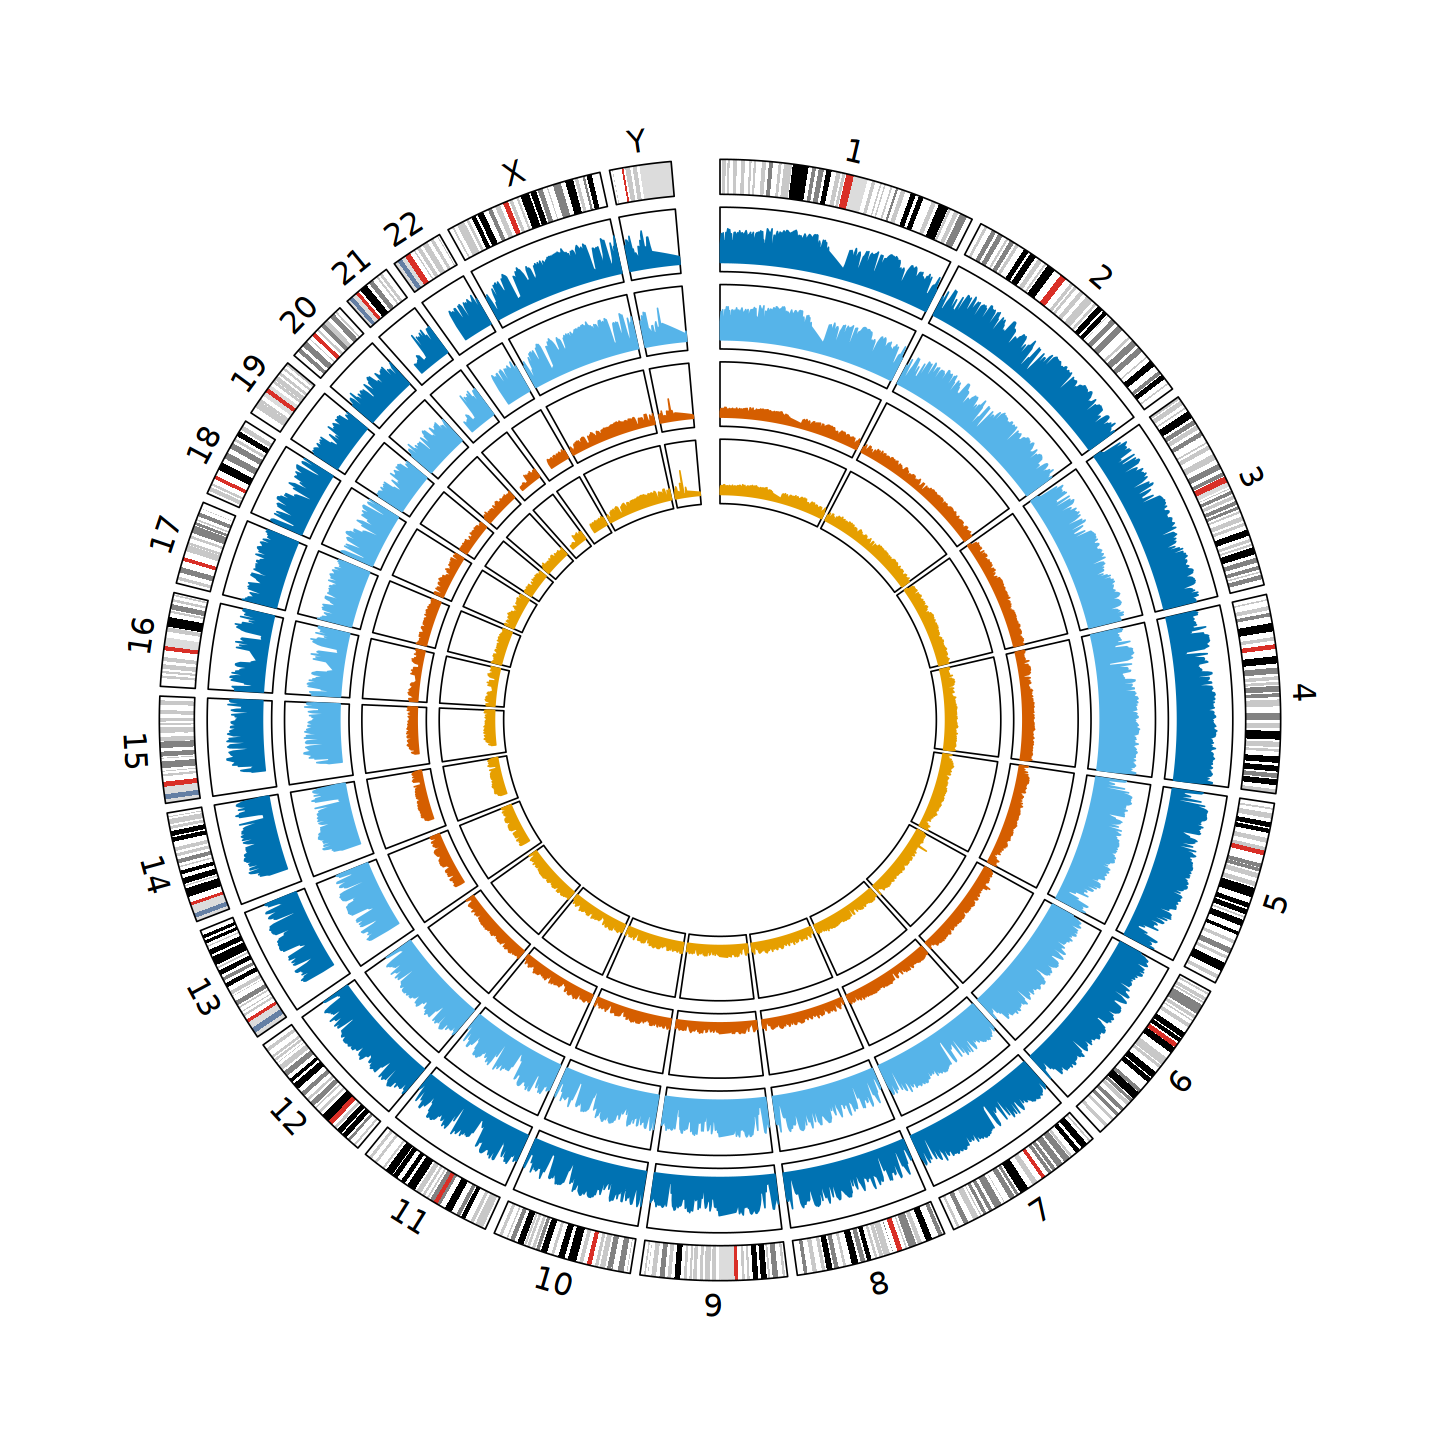

In [ ]:
# 5. Setup Circos plot parameters
options(repr.plot.width = 12, repr.plot.height = 12)

circos.par(
    start.degree = 90, track.margin = c(0.01, 0.01),
    gap.after = c(rep(1, length(standard_chromosome) - 1), 5))

circos.initializeWithIdeogram(
    species = "hg19", 
    plotType = c("ideogram", "labels"),
    chromosome.index = standard_chromosome,
    ideogram.height = convert_height(4, "mm"),
    track.height = 0.1, labels.cex = 1.5, axis.labels.cex = 0.6)

# 6. Define helper function for plotting signal tracks
plot_peak_track <- function(
    data_col, color, ylimit = NULL, track_height = 0.1) {

    df_track <- bin_df[, c("chr", "start", "end", data_col)]
    df_track <- df_track[!is.na(df_track[[data_col]]), ]

    circos.genomicTrack(
        df_track, track.height = track_height, ylim = ylimit,
        panel.fun = function(region, value, ...) {
            circos.genomicLines(
                region, value,
                area = TRUE, baseline = 0,
                col = color, border = color)
        })
}

# 7. Plot individual signal tracks
plot_peak_track(names(meth_list)[1], color = "#0072B2", ylimit = c(0, 100))
plot_peak_track(names(meth_list)[2], color = "#56B4E9", ylimit = c(0, 100))
plot_peak_track(names(meth_list)[3], color = "#D55E00", ylimit = c(0, 100))
plot_peak_track(names(meth_list)[4], color = "#E69F00", ylimit = c(0, 100))

# 8. Clear Circos parameters
circos.clear()

## 4). Genomic Signal Plot

In [32]:
chr_idx <- "chr2"
chrom_sizes <- seqlengths(genome)[chr_idx]
bins <- tileGenome(
    seqlengths = chrom_sizes, tilewidth = 1e6,
    cut.last.tile.in.chrom = TRUE)
names(bins) <- floor((start(bins) + end(bins)) / 2)

In [33]:
bin_stats_list <- lapply(names(meth_list), function(idx) {
    gr <- meth_list[[idx]]
    gr <- gr[seqnames(gr) == chr_idx]
    hits <- findOverlaps(gr, bins, ignore.strand = TRUE)

    df <- data.table::data.table(
        bin_idx = subjectHits(hits),
        numCs = gr$numCs[queryHits(hits)],
        numTs = gr$numTs[queryHits(hits)])

    bin_stats <- df[, list(
        numCs = sum(numCs), numTs = sum(numTs)), by = bin_idx]
    bin_stats[, meth := numCs / (numCs + numTs) * 100]

    result <- bins[bin_stats$bin_idx]
    result$meth <- bin_stats$meth
    result$numCs <- bin_stats$numCs
    result$numTs <- bin_stats$numTs
    result$sample <- idx
    names(result) <- NULL
    return(result)
})

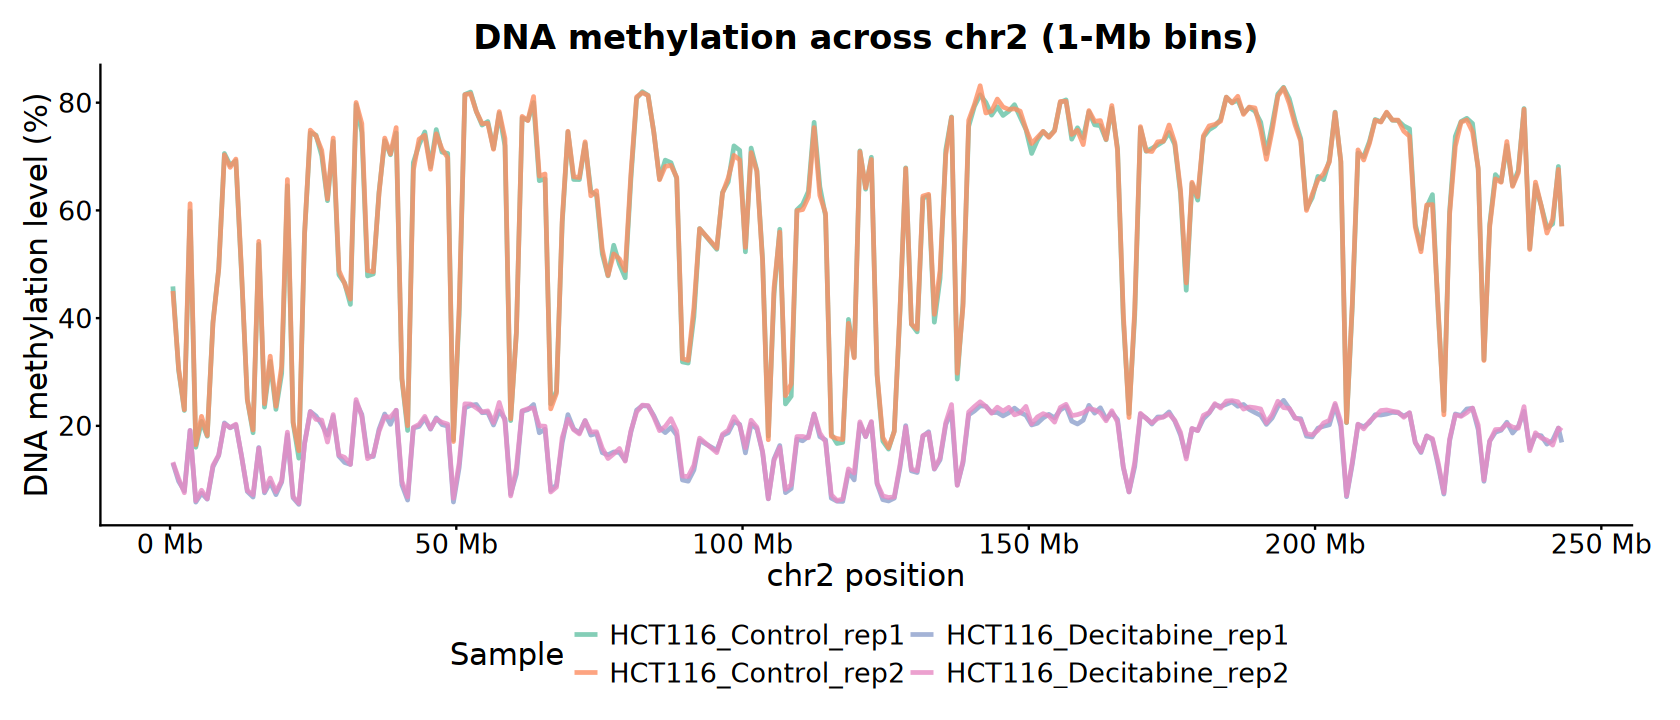

In [34]:
options(repr.plot.width = 14, repr.plot.height = 6)

do.call(c, bin_stats_list) |>
    as.data.frame() |>
    mutate(position = (start + end) / 2) |>
ggplot(aes(x = position, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    scale_x_continuous(
        limits = c(1, chrom_sizes), breaks = scales::breaks_width(5e7),
        labels = function(x) {paste0(x / 1e6, " Mb")}) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = paste0("DNA methylation across ", chr_idx, " (1-Mb bins)"),
        x = paste0(chr_idx, " position"), 
        y = "DNA methylation level (%)",
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 2, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Metagene Profile

In [35]:
gtf <- import(gtf_file)

GENES <- subset(
    gtf, type == "gene" & gene_type == "protein_coding",
    select = c("gene_id", "gene_name")
)

PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

In [36]:
CGI <- read.table(
    "~/reference/Homo_sapiens/hg19/cpgIslandExt.txt",
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length",
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [37]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  12222    8123 


    Promoter non_Promoter 
       10870        10846 

### a). Genes

In [38]:
gene_mat_List <- lapply(
    meth_list, normalizeToMatrix, GENES, value_column = "meth", 
    extend = 2000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.4, background = NA, smooth = FALSE)

In [39]:
partition <- PROMOTERS$CGI_status

col_cluster <- c(CGI  = "#756BB1", non_CGI = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 50, 100),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "CpG status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [40]:
ht_list <- Heatmap(
    partition, name = "Genes", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(gene_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        gene_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-2kb", "TSS", "TES", "+2kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 100)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

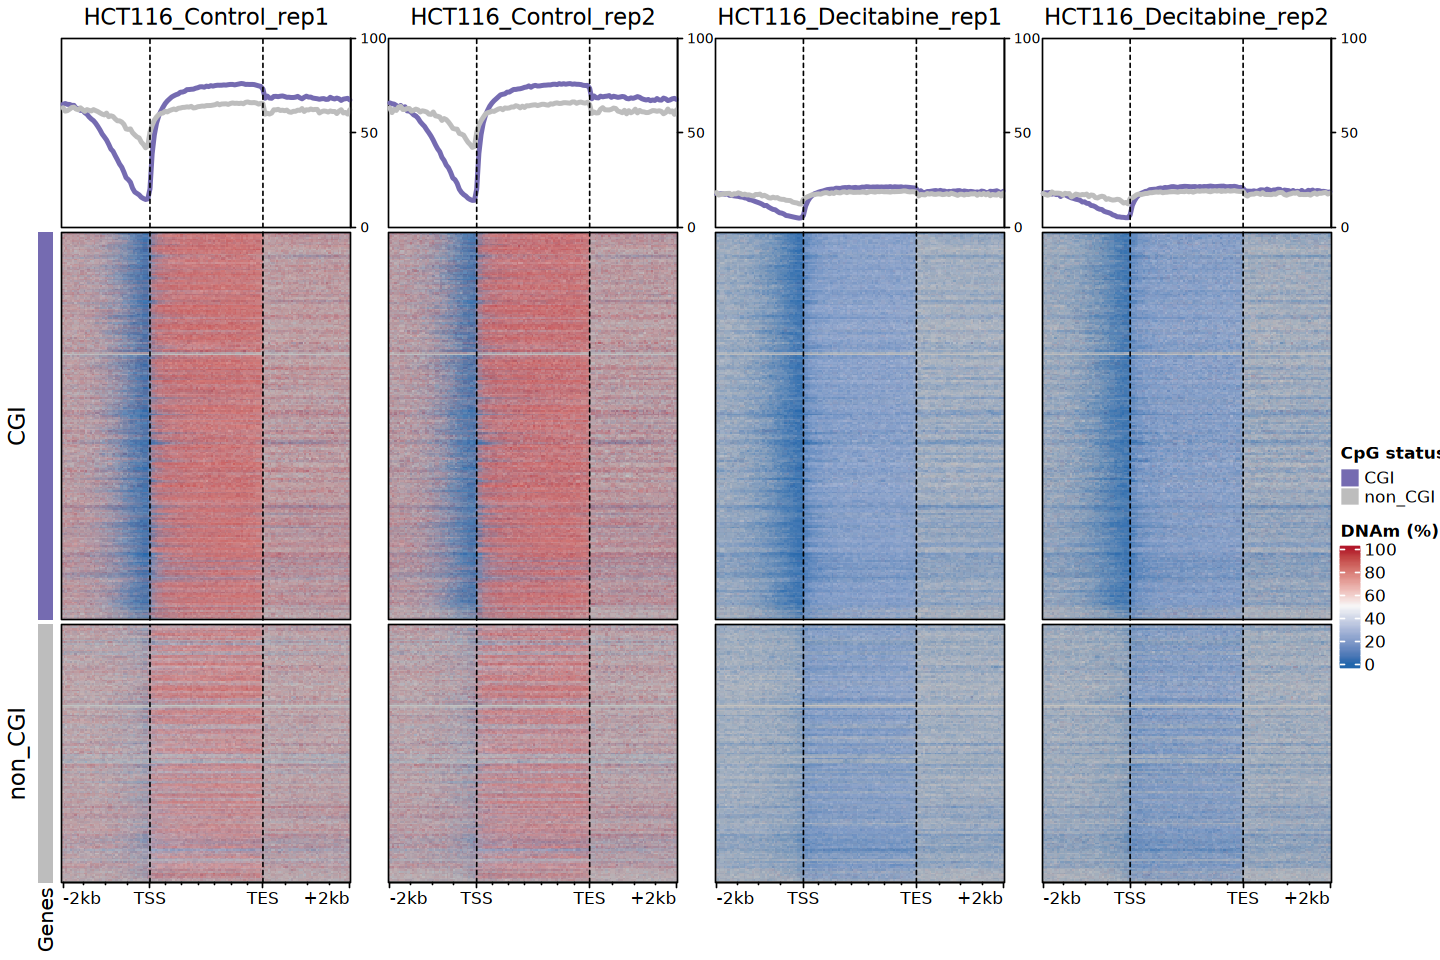

In [41]:
options(repr.plot.width = 12, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(gene_mat_List))), "mm"))

In [42]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

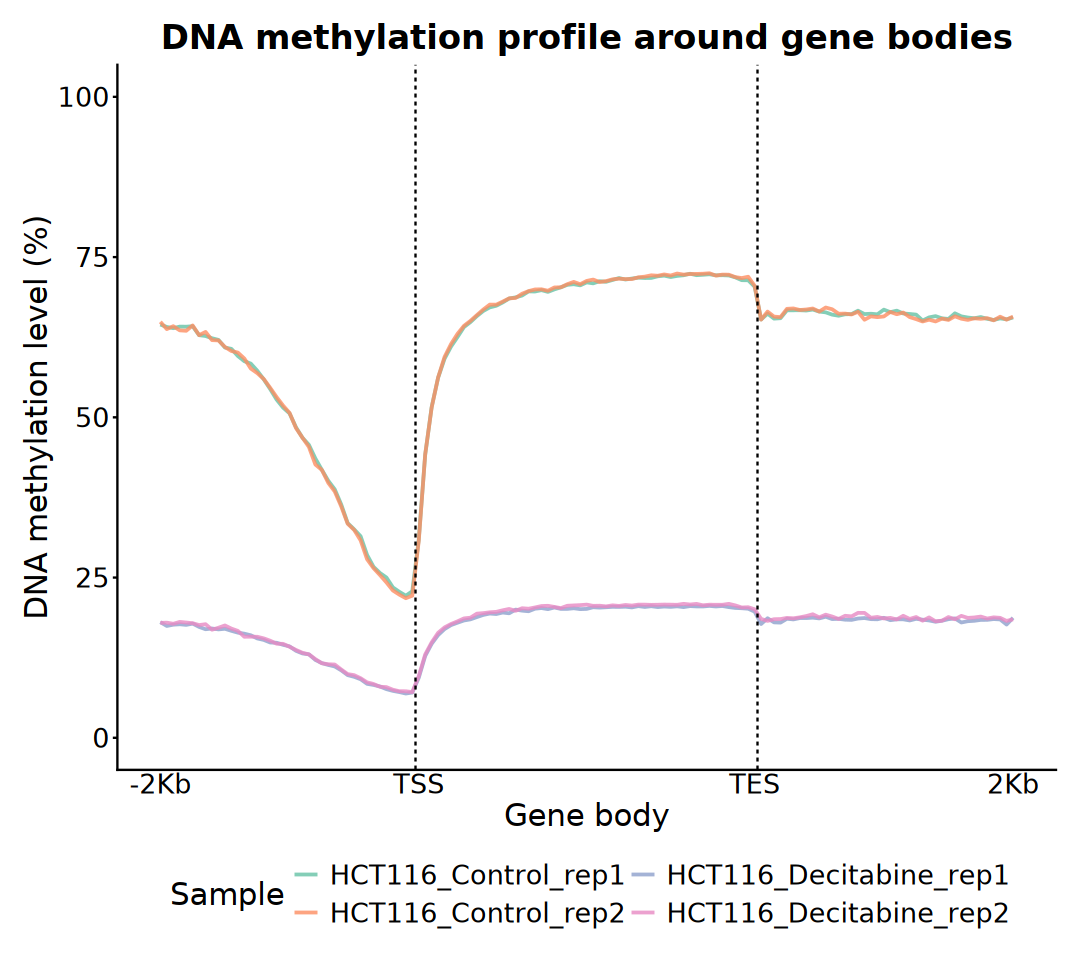

In [43]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = "Gene body", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### b). CGI

In [ ]:
cgi_mat_List <- lapply(
    meth_list, normalizeToMatrix, CGI, value_column = "meth",
    extend = 4000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.3, background = NA, smooth = FALSE)

In [45]:
partition <- CGI$Promoter_status

col_cluster <- c(Promoter  = "#1B9E77", non_Promoter = "#BDBDBD")
col_meth <- circlize::colorRamp2(
    breaks = c(0, 50, 100),
    colors = c("#2166AC", "#F7F7F7", "#B2182B"))

lgd_cluster <- Legend(
    at = names(col_cluster), title = "Promoter status",
    legend_gp = gpar(fill = col_cluster))
lgd_meth <- Legend(col_fun = col_meth, title = "DNAm (%)")

In [46]:
ht_list <- Heatmap(
    partition, name = "CGI", col = col_cluster, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE)

for (idx in names(cgi_mat_List)) {
    ht_list <- ht_list + EnrichedHeatmap(
        cgi_mat_List[[idx]], name = idx, column_title = idx, 
        col = col_meth, show_heatmap_legend = FALSE, use_raster = TRUE,
        axis_name = c("-4kb", "start", "end", "+4kb"),
        top_annotation = HeatmapAnnotation(
            lines = anno_enriched(
                gp = gpar(col = col_cluster, lwd = 3),
                ylim = c(0, 100)),
            height = unit(4, "cm"),
            show_legend = FALSE))
}

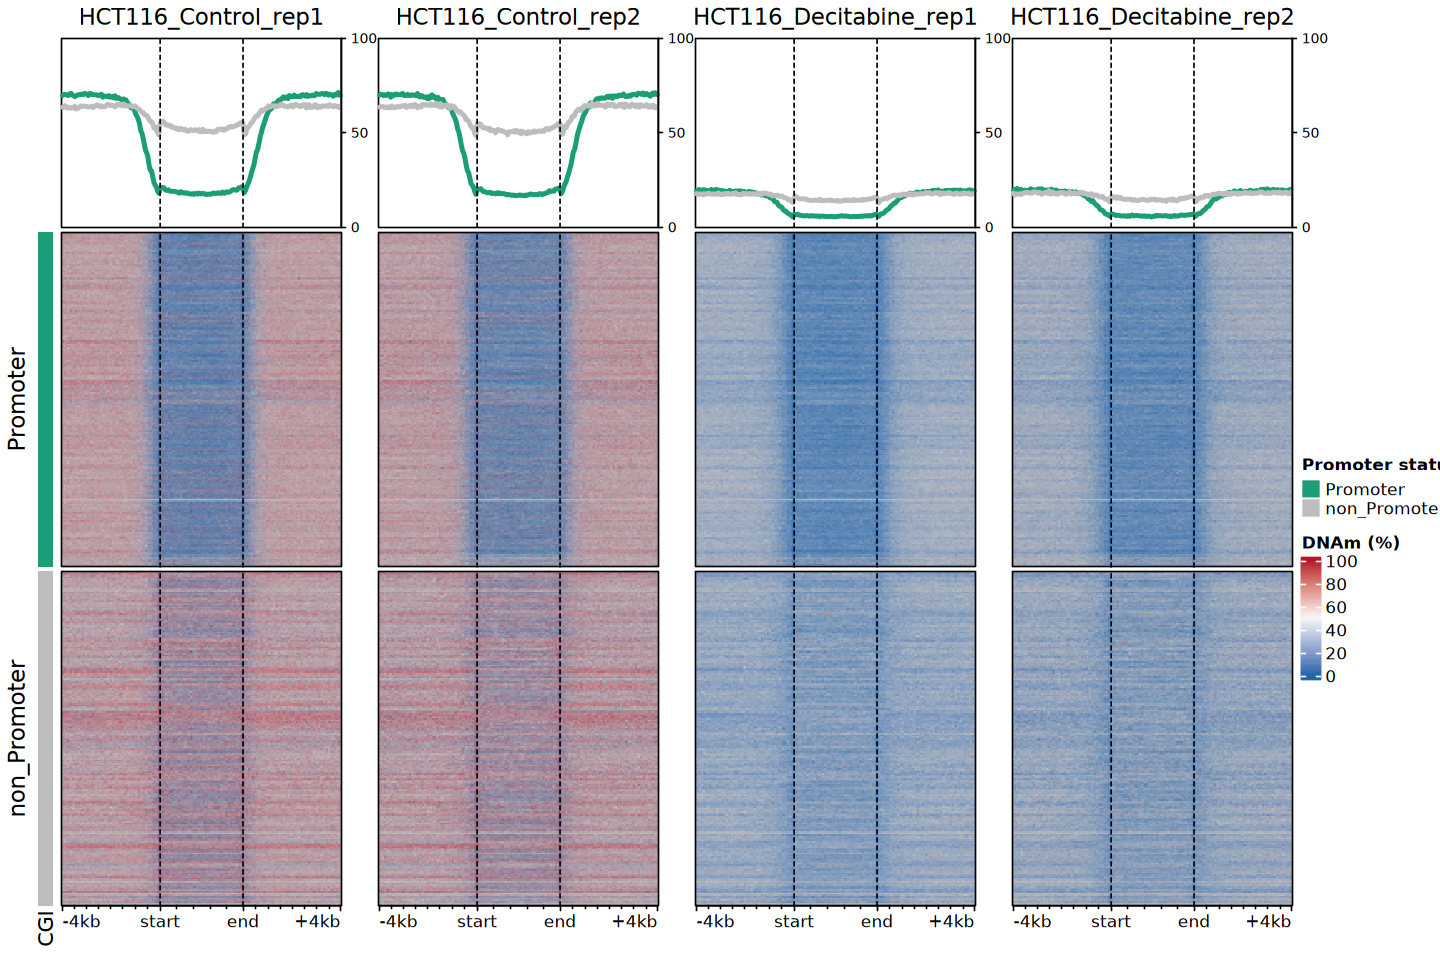

In [47]:
options(repr.plot.width = 12, repr.plot.height = 8)

draw(
    ht_list, split = partition, 
    annotation_legend_list = list(lgd_cluster, lgd_meth),
    ht_gap = unit(c(2, rep(8, length(cgi_mat_List))), "mm"))

In [48]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    mutate(pos = factor(pos, levels = position_index)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

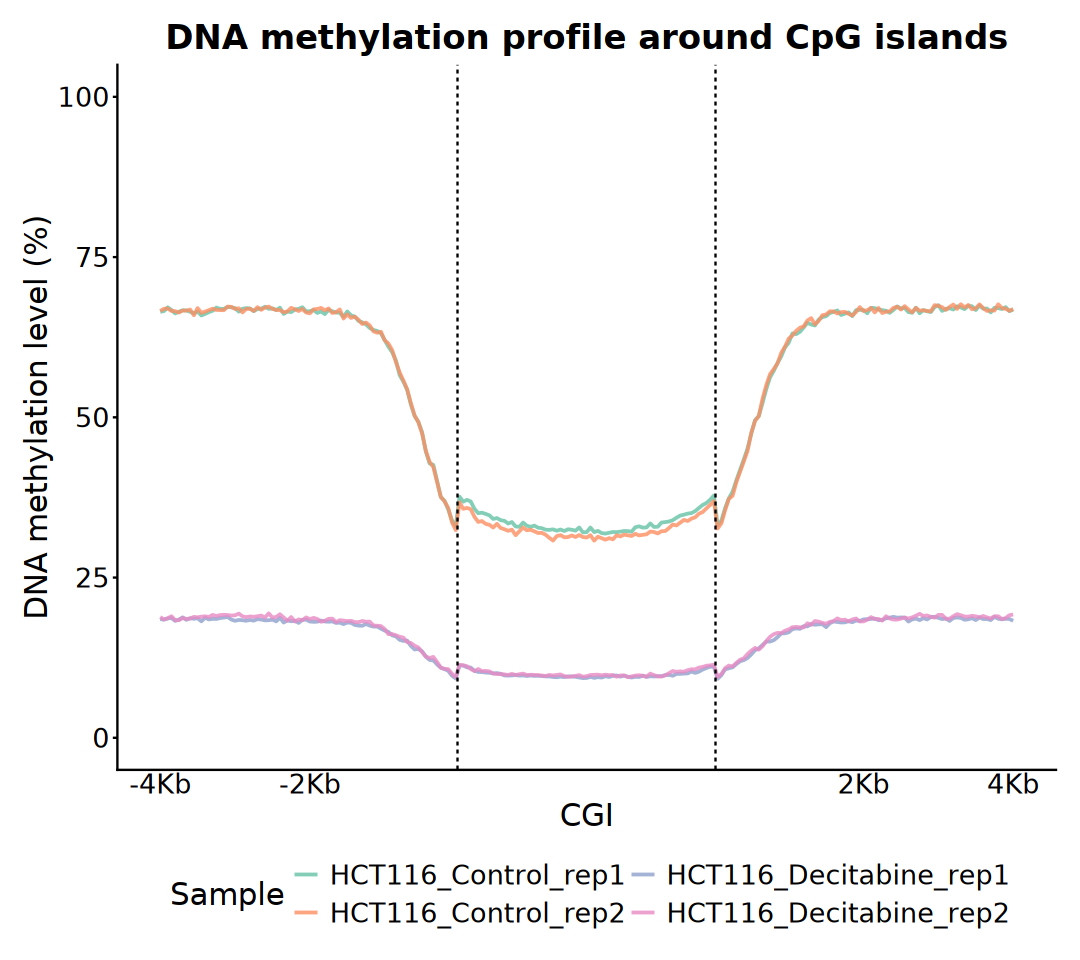

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = pos, y = meth, group = sample)) +
    geom_line(aes(color = sample), linewidth = .8, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    scale_x_discrete(
        breaks = c("u1", "u41", "d40", "d80"), 
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb"),
        expand = c(0.05, 0.05)) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around CpG islands",
        x = "CGI", y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

In [50]:
get_region_data <- function(
    gr, region, sample_id, method = c("mean", "ratio"),
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)
    region_mean <- rep(NA_real_, length(region))

    if (length(hits) == 0) {
        mcols(region)[[sample_id]] <- region_mean
        return(region)
    }

    cpg_idx <- queryHits(hits)
    region_idx <- subjectHits(hits)

    if (method == "mean") {
        vals <- mcols(gr)[[meth_col]]
        region_mean <- tapply(vals[cpg_idx], region_idx, mean, na.rm = TRUE)
        result <- rep(NA_real_, length(region))
        result[as.integer(names(region_mean))] <- region_mean
    } else {
        numCs <- mcols(gr)[[numCs_col]]
        numTs <- mcols(gr)[[numTs_col]]
        sumCs <- tapply(numCs[cpg_idx], region_idx, sum, na.rm = TRUE)
        sumTs <- tapply(numTs[cpg_idx], region_idx, sum, na.rm = TRUE)
        region_mean <- sumCs / (sumCs + sumTs) * 100
        result <- rep(NA_real_, length(region))
        result[as.integer(names(region_mean))] <- region_mean
    }
    mcols(region)[[sample_id]] <- result
    return(region)
}

In [51]:
region_mat <- Reduce(function(region, sample) {
    get_region_data(
        gr = meth_list[[sample]], region = region, sample_id = sample)
    }, names(meth_list), init = CGI)

In [52]:
plot_df <- region_mat |> mcols() |> as.data.frame() |>
    dplyr::select(Promoter_status, names(meth_list)) |>
    pivot_longer(
        cols = - Promoter_status, names_to = "sample", values_to = "meth") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

head(plot_df)

Promoter_status,sample,meth,Cell,Group,Replicate
<fct>,<chr>,<dbl>,<chr>,<fct>,<fct>
non_Promoter,HCT116_Control_rep1,0.00000,HCT116,Control,rep1
non_Promoter,HCT116_Control_rep2,0.00000,HCT116,Control,rep2
non_Promoter,HCT116_Decitabine_rep1,0.00000,HCT116,Decitabine,rep1
non_Promoter,HCT116_Decitabine_rep2,0.00000,HCT116,Decitabine,rep2
non_Promoter,HCT116_Control_rep1,82.41758,HCT116,Control,rep1
non_Promoter,HCT116_Control_rep2,92.18750,HCT116,Control,rep2


In [53]:
suppressPackageStartupMessages(library(ggridges))

Picking joint bandwidth of 1.81

Picking joint bandwidth of 3.6



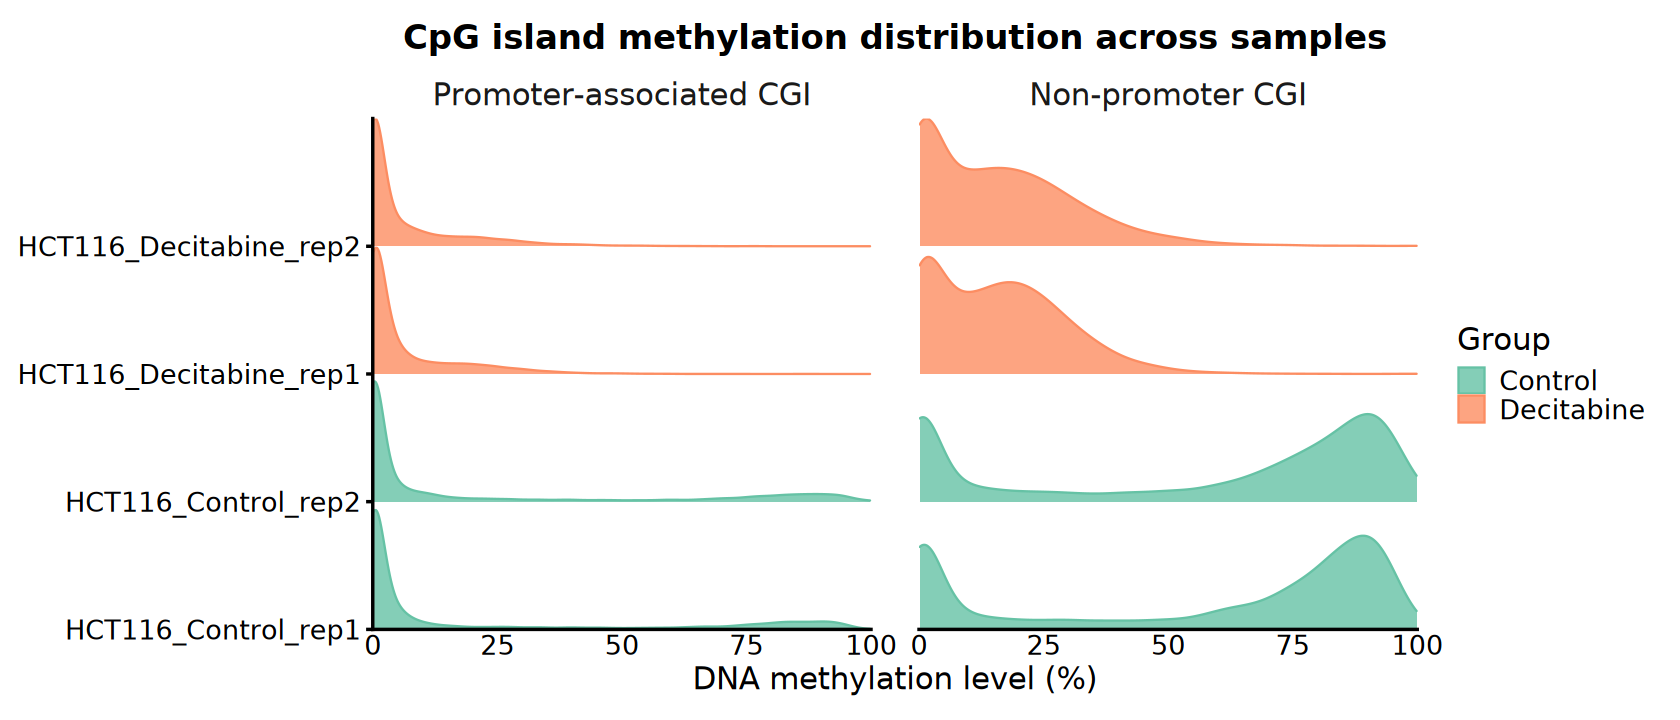

In [54]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(plot_df, aes(x = meth, y = sample)) +
    geom_density_ridges(
        aes(color = Group, fill = Group), alpha = 0.8, 
        scale = 1, na.rm = TRUE) +
    facet_wrap(~ Promoter_status, labeller = labeller(
        Promoter_status = c(
            "Promoter" = "Promoter-associated CGI",
            "non_Promoter" = "Non-promoter CGI"))) +
    scale_x_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG island methylation distribution across samples",
        x = "DNA methylation level (%)", y = NULL) +
    theme_classic(base_size = 16) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16),
        axis.ticks.x = element_blank())

## 6). DNAm Distribution

In [55]:
gene <- genes(txdb)
promoter <- promoters(gene, upstream = 2000, downstream = 500)
downstream <- flank(gene, width = 2000, start = FALSE)

exon <- exonsBy(txdb, by = "gene")
intron <- intronsByTranscript(txdb)

utr5 <- fiveUTRsByTranscript(txdb)
cds <- cdsBy(txdb, by = "gene")
utr3 <- threeUTRsByTranscript(txdb)

gap <- c(gene, promoter, downstream) |> unstrand() |> gaps()
intergenic <- gap[strand(gap) == "*"]

  24 genes were dropped because they have exons located on both strands of the
  same reference sequence or on more than one reference sequence, so cannot be
  represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.



In [56]:
# CGI shore = ±2kb around CGI excluding CGI
# CGI shelf = 2–4kb around CGI excluding 0–2kb, CGI
cgi_2kb <- resize(CGI, width = width(CGI) + 4000, fix = "center")
cgi_shore <- setdiff(cgi_2kb, CGI)
cgi_4kb <- resize(CGI, width = width(CGI) + 8000, fix = "center")
cgi_shelf <- setdiff(cgi_4kb, cgi_2kb)

In [57]:
region_list <- list(
    CGI = CGI, CGI_Shore = cgi_shore, CGI_Shelf = cgi_shelf,
    Promoter = promoter, Exon = unlist(exon), Intron = unlist(intron),
    FiveUTR = unlist(utr5), CDS = unlist(cds), ThreeUTR = unlist(utr3),
    Downstream = downstream, Intergenic = intergenic
)

In [58]:
get_profile_data <- function(
    gr, region, region_id, bin = 50, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)

    if(length(hits) == 0) return(NULL)

    gr_sub <- gr[queryHits(hits)]
    region_sub <- region[subjectHits(hits)]

    rel_pos <- (start(gr_sub) - start(region_sub)) / width(region_sub)
    is_minus <- as.character(strand(region_sub)) == "-"
    rel_pos[is_minus] <- 1 - rel_pos[is_minus]

    bin_idx <- ceiling(rel_pos * bin)
    bin_idx[bin_idx == 0] <- 1
    bin_idx[bin_idx > bin] <- bin

    if (method == "mean") {
        vals <- mcols(gr_sub)[[meth_col]]
        mean <- mean(vals, na.rm = TRUE)
        df <- tibble(bin = bin_idx, meth = vals) |> 
            group_by(bin) |>
            summarise(mean = mean(meth, na.rm = TRUE), .groups = "drop") |>
            mutate(region = region_id)
    } else if (method == "ratio") {
        numCs <- mcols(gr_sub)[[numCs_col]]
        numTs <- mcols(gr_sub)[[numTs_col]]
        df <- tibble(bin = bin_idx, numCs = numCs, numTs = numTs) |>
            group_by(bin) |>
            summarise(
                mean = sum(numCs) / sum(numCs + numTs) * 100, 
                .groups = "drop") |>
            mutate(region = region_id)
    }

    return(df)
}

In [59]:
region_index <- c(
    "Promoter", "FiveUTR", "Exon", "Intron", "ThreeUTR", 
    "Downstream", "Intergenic")

profiles_list <- list()

for (sample_idx in names(meth_list)) {
    meth <- meth_list[[sample_idx]]
    result <- lapply(region_index, function(idx) {
        region <- region_list[[idx]]
        df <- get_profile_data(
            meth, region, idx, bin = 50, method = "ratio")
        return(df)
    })

    profiles_list[[sample_idx]] <- bind_rows(result) |>
        mutate(
            sample = sample_idx, 
            region = factor(region, levels = region_index))
}

In [60]:
plot_df <- bind_rows(profiles_list) |>
    mutate(region_idx = as.numeric(region) - 1) |>
    mutate(global_idx = (region_idx * 50) + bin)

head(plot_df)

bin,mean,region,sample,region_idx,global_idx
<dbl>,<dbl>,<fct>,<chr>,<dbl>,<dbl>
1,61.21813,Promoter,HCT116_Control_rep1,0,1
2,60.94466,Promoter,HCT116_Control_rep1,0,2
3,60.66147,Promoter,HCT116_Control_rep1,0,3
4,60.34659,Promoter,HCT116_Control_rep1,0,4
5,60.39110,Promoter,HCT116_Control_rep1,0,5
6,60.13497,Promoter,HCT116_Control_rep1,0,6


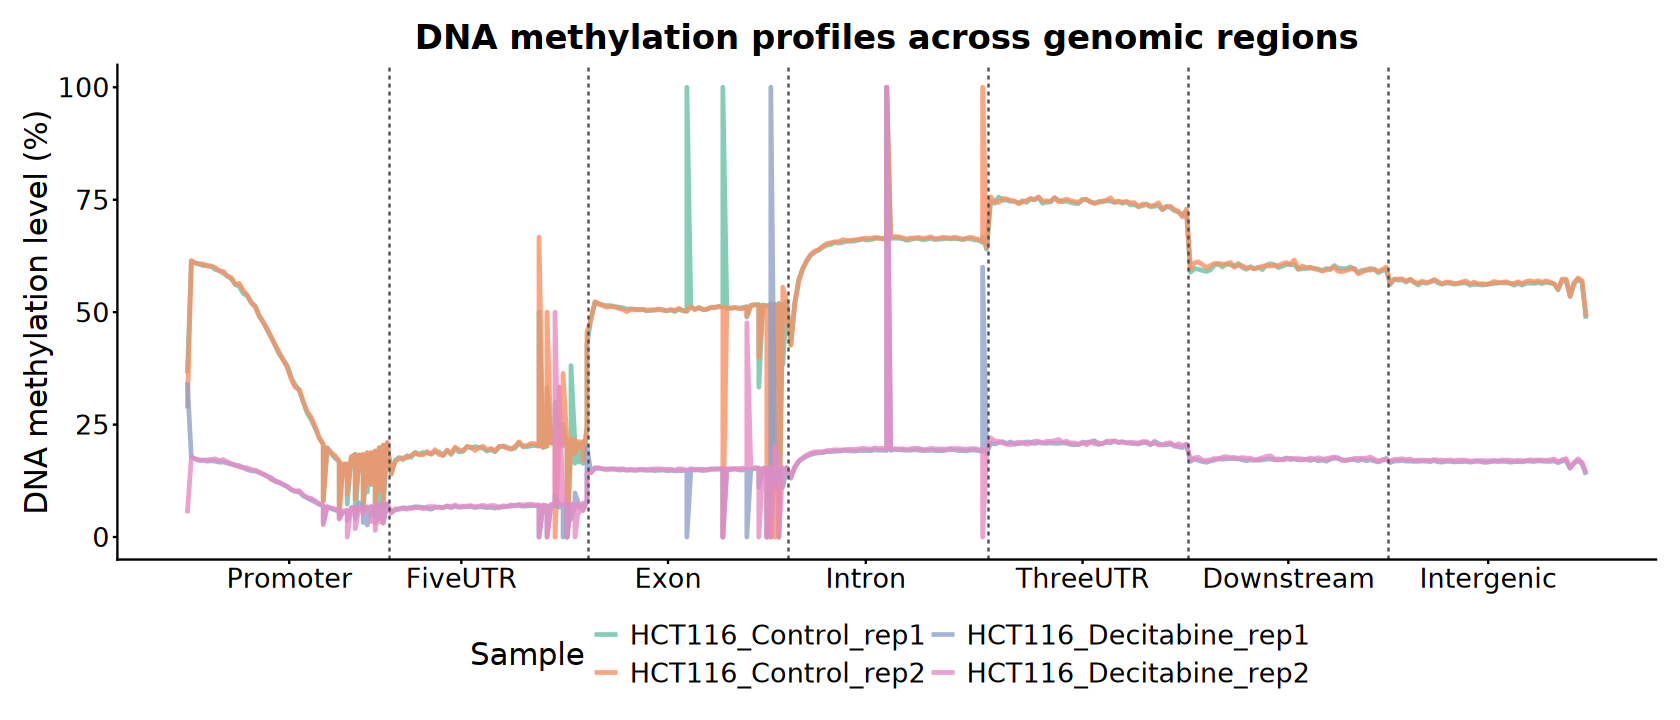

In [61]:
options(repr.plot.width = 14, repr.plot.height = 6)

x_labels_pos <- plot_df |> group_by(region) |>
    summarise(center_idx = mean(global_idx), .groups = "drop")
vlines_pos <- seq(50 + 0.5, max(plot_df$global_idx) - 50 + 0.5, by = 50)

ggplot(plot_df, aes(x = global_idx, y = mean, group = sample)) +
    geom_line(aes(color = sample), linewidth = 1, alpha = .8, na.rm = TRUE) +
    geom_vline(xintercept = vlines_pos, color = "grey30", linetype = "dashed") +
    scale_x_continuous(
        breaks = x_labels_pos$center_idx, 
        labels = x_labels_pos$region) +
    scale_color_brewer(palette = "Set2") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profiles across genomic regions",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Sample") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [62]:
get_region_data <- function(
    gr, region_list, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    map_dfr(names(region_list), function(idx) {
        hits <- findOverlaps(gr, region_list[[idx]], ignore.strand = TRUE)
        sub_gr <- gr[queryHits(hits)]

        if (method == "mean") {
            vals <- mcols(sub_gr)[[meth_col]]
            mean <- mean(vals, na.rm = TRUE)
        } else if (method == "ratio") {
            numCs <- mcols(sub_gr)[[numCs_col]]
            numTs <- mcols(sub_gr)[[numTs_col]]

            sumCs <- sum(numCs, na.rm = TRUE)
            sumTs <- sum(numTs, na.rm = TRUE)
            mean <- sumCs / (sumCs + sumTs) * 100
        }
        tibble(region = idx, numCpG = length(sub_gr), mean = mean)
    })
}

In [63]:
meth_df <- imap_dfr(meth_list, function(gr, sample_id) {
    get_region_data(gr = gr, region_list = region_list, method = "ratio")
}, .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(region = factor(region, levels = names(region_list)))

head(meth_df)

sample,region,numCpG,mean,Cell,Group,Replicate
<chr>,<fct>,<int>,<dbl>,<chr>,<fct>,<fct>
HCT116_Control_rep1,CGI,1743094,26.20858,HCT116,Control,rep1
HCT116_Control_rep1,CGI_Shore,1531933,53.52034,HCT116,Control,rep1
HCT116_Control_rep1,CGI_Shelf,950388,70.33473,HCT116,Control,rep1
HCT116_Control_rep1,Promoter,2060829,29.46374,HCT116,Control,rep1
HCT116_Control_rep1,Exon,5765944,50.97500,HCT116,Control,rep1
HCT116_Control_rep1,Intron,127233839,64.31579,HCT116,Control,rep1


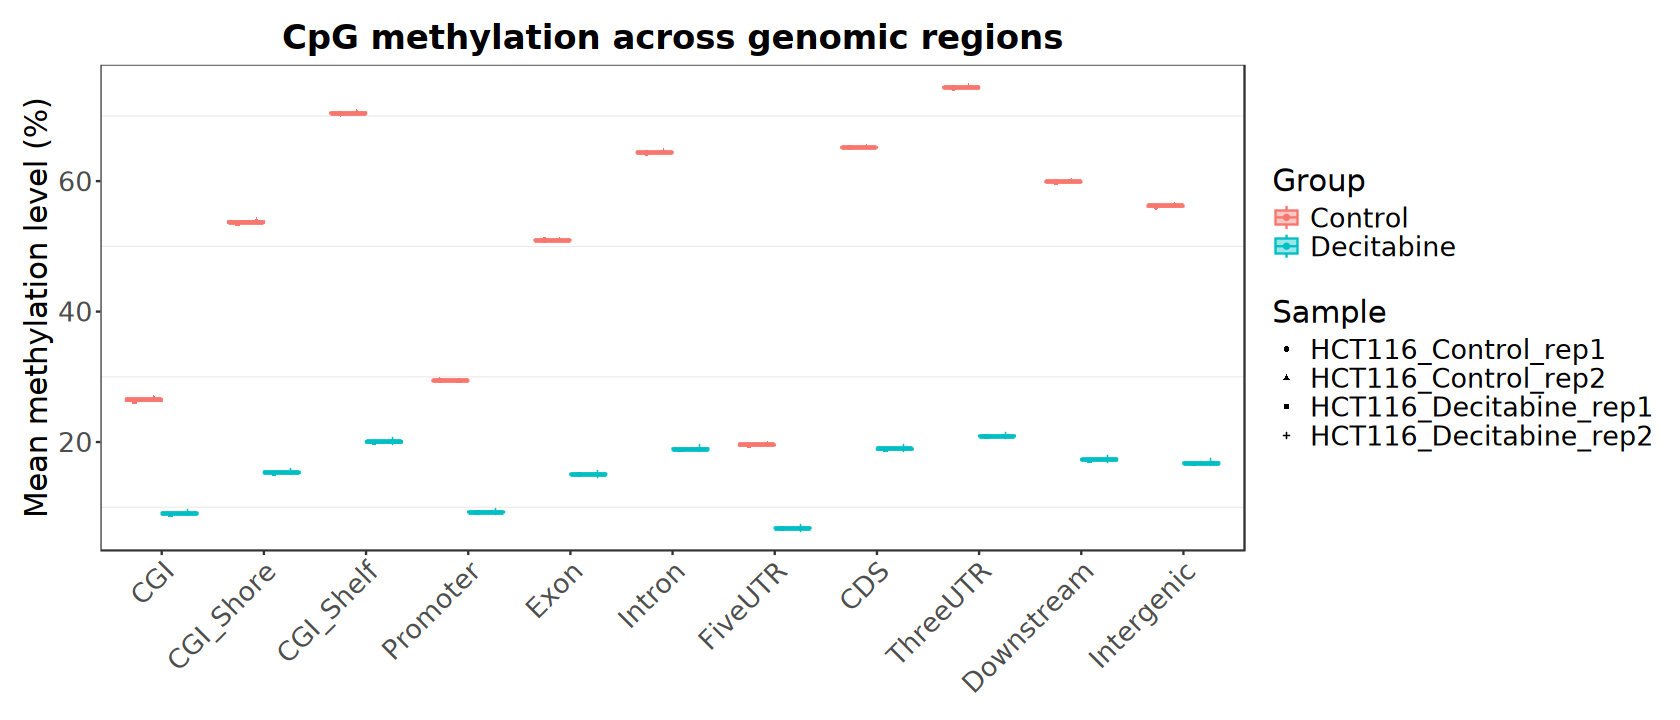

In [64]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean)) +
    geom_boxplot(
        aes(color = Group, fill = Group), 
        position = position_dodge(width = 0.7),
        width = 0.7, outlier.shape = NA, alpha = 0.4) +
    geom_point(
        aes(color = Group, shape = sample), 
        position = position_jitterdodge(
            jitter.width = 0.1, dodge.width = 0.7), 
        size = 1, alpha = 1) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Group", fill = "Group", shape = "Sample") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.grid.major = element_blank(), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "right", 
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

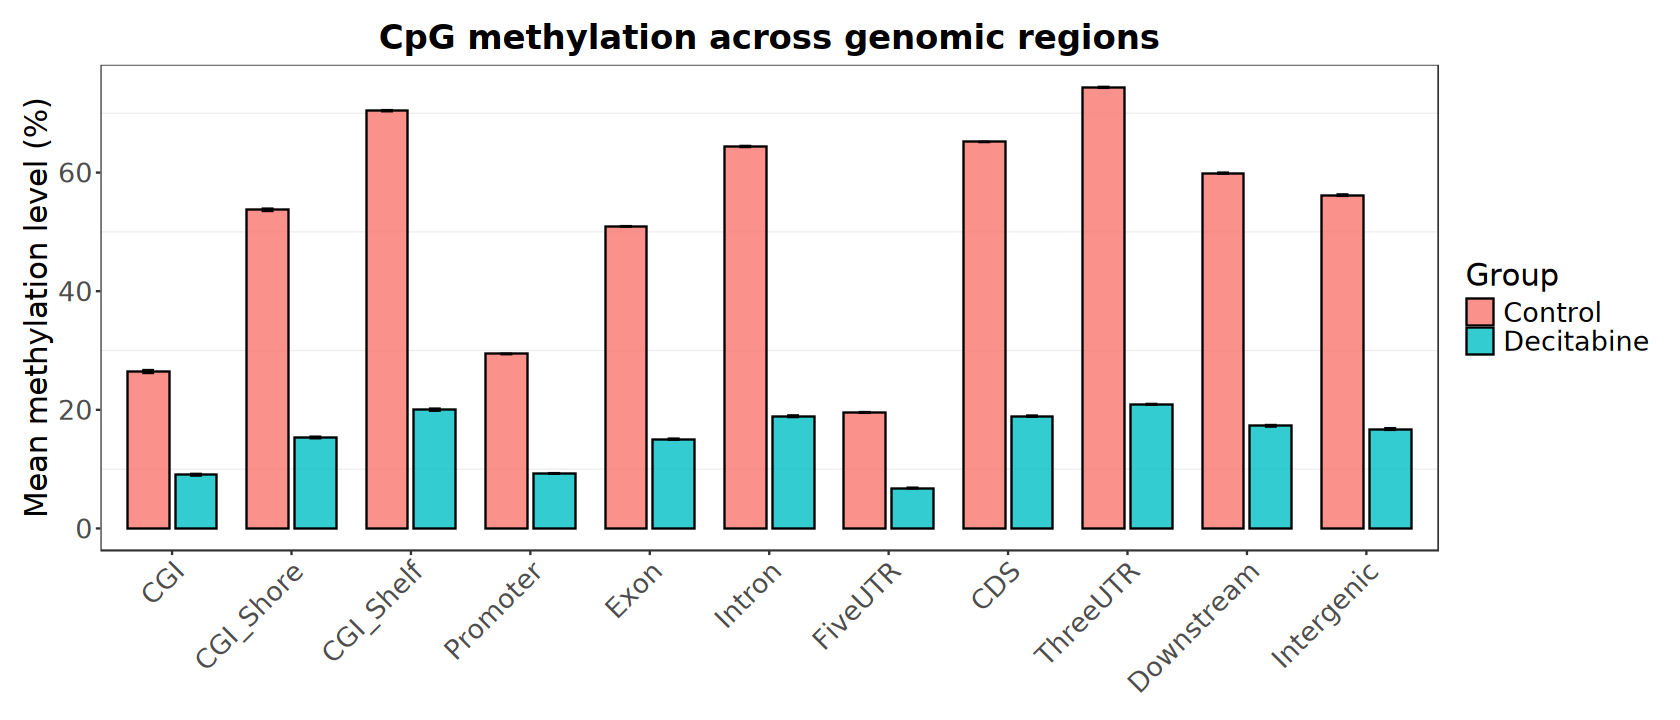

In [65]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(meth_df, aes(x = region, y = mean, color = Group, fill = Group)) +
    geom_bar(
        stat = "summary", fun = "mean", 
        position = position_dodge(width = 0.8), 
        color = "black", alpha = 0.8, width = 0.7) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black",
        position = position_dodge(width = 0.8), width = 0.2) +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

# * Reference